In [1]:
import pandas as pd


In [2]:
# Load raw transcation data for initial exploration
df = pd.read_csv("payment.csv")
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (50000, 25)


,transaction_id,timestamp,user_id,device_id,merchant_name,merchant_category,gateway_name,amount,currency,payment_method,...,response_time_ms,settlement_id,settled_amount,mdr_fee,settlement_status,settled_date,risk_score,chargeback_flag,refund_status,refund_amount
0,TXN_0021367,2026-05-17 10:09:37,USR_26248,DEV_25264,Meesho,E-commerce,PayU,1007.22,INR,UPI,...,336.0,NaN,NaN,20.14,Not Applicable,NaN,31.54,0,Not Refunded,0.0
1,TXN_0003228,2026-02-07 12:51:27,USR_16739,DEV_21488,Flipkart,E-commerce,Razorpay,130.32,INR,UPI,...,1411.0,SET_916887,130.32,1.95,Settled,2026-02-11 12:51:27,30.00,0,Not Refunded,0.0
2,TXN_0047958,2026-04-03 09:35:22,USR_19282,DEV_24379,BookMyShow,Entertainment,PayU,102.26,INR,UPI,...,424.0,SET_740417,102.26,1.23,Settled,2026-04-05 09:35:22,47.16,0,Not Refunded,0.0
3,TXN_0010902,2026-02-09 02:05:36,USR_22881,DEV_29644,Nykaa,Beauty,Razorpay,705.13,INR,Credit Card,...,151.0,SET_200209,705.13,8.46,Settled,2026-02-12 02:05:36,37.34,0,Not Refunded,0.0
4,TXN_0032753,2026-03-01 03:00:54,USR_25648,DEV_15551,Amazon,E-commerce,Cashfree,262.43,INR,UPI,...,323.0,SET_830870,262.43,4.72,Pending,NaN,84.54,0,Not Refunded,0.0


In [3]:
#  check data types and missing values for each coloumn
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   transaction_id     50000 non-null  object 
 1   timestamp          50000 non-null  object 
 2   user_id            49501 non-null  object 
 3   device_id          49600 non-null  object 
 4   merchant_name      50000 non-null  object 
 5   merchant_category  50000 non-null  object 
 6   gateway_name       49501 non-null  object 
 7   amount             50000 non-null  float64
 8   currency           50000 non-null  object 
 9   payment_method     50000 non-null  object 
 10  card_network       50000 non-null  object 
 11  issuer_bank        49501 non-null  object 
 12  device_type        50000 non-null  object 
 13  status             50000 non-null  object 
 14  failure_reason     7772 non-null   object 
 15  response_time_ms   49500 non-null  float64
 16  settlement_id      405

In [4]:
# calculate missing values count and percentage
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing count': missing,
    'Missing %': missing_percent.round(2)

})
missing_summary[missing_summary['Missing count'] > 0].sort_values('Missing count', ascending=False)



,Missing count,Missing %
failure_reason,42228,84.46
settled_date,13650,27.30
settlement_id,9428,18.86
settled_amount,9428,18.86
risk_score,752,1.50
response_time_ms,500,1.00
user_id,499,1.00
gateway_name,499,1.00
issuer_bank,499,1.00
device_id,400,0.80


In [5]:
# Check if missing gateway_name, issuer_bank, user_id are the same rows
same_rows = df[df['gateway_name'].isnull() & df['issuer_bank'].isnull() & df['user_id'].isnull()]
print(f"Rows where all three are missing together: {len(same_rows)}")

Rows where all three are missing together: 0


In [6]:
# fill missing values in text (categorical) columns with "unknown"
text_fill = ['gateway_name', 'issuer_bank', 'device_id', 'user_id']
for col in text_fill:
    df[col] = df[col].fillna('Unknown')
    print("text columns filled.checking missing values now:")
    print(df[text_fill].isnull().sum())

text columns filled.checking missing values now:
gateway_name      0
issuer_bank     499
device_id       400
user_id         499
dtype: int64
text columns filled.checking missing values now:
gateway_name      0
issuer_bank       0
device_id       400
user_id         499
dtype: int64
text columns filled.checking missing values now:
gateway_name      0
issuer_bank       0
device_id         0
user_id         499
dtype: int64
text columns filled.checking missing values now:
gateway_name    0
issuer_bank     0
device_id       0
user_id         0
dtype: int64


In [7]:
# fill missing values in numeric columns with median(robust to outlier)
df['response_time_ms'] = df['response_time_ms'].fillna(df['response_time_ms'].median())
df['risk_score'] = df['risk_score'].fillna(df['risk_score'].median())
print(df[['response_time_ms', 'risk_score']].isnull().sum())

response_time_ms    0
risk_score          0
dtype: int64


In [8]:
 df.isnull().sum()

transaction_id           0
timestamp                0
user_id                  0
device_id                0
merchant_name            0
merchant_category        0
gateway_name             0
amount                   0
currency                 0
payment_method           0
card_network             0
issuer_bank              0
device_type              0
status                   0
failure_reason       42228
response_time_ms         0
settlement_id         9428
settled_amount        9428
mdr_fee                  0
settlement_status        0
settled_date         13650
risk_score               0
chargeback_flag          0
refund_status            0
refund_amount            0
dtype: int64

In [9]:
# check unique values
df['payment_method'].unique()

array(['UPI', 'Credit Card', 'Debit Card', 'Wallet', 'Net Banking',
       'DEBIT CARD', 'CREDIT CARD', 'UPI ', 'Upi', 'debit card',
       'NET BANKING', 'net banking', 'upi', 'credit card', 'wallet',
       'WALLET'], dtype=object)

In [10]:
# remove extra space
df['payment_method'] = df['payment_method'].str.strip().str.upper()
# fix and verrify
df['payment_method'].unique()

array(['UPI', 'CREDIT CARD', 'DEBIT CARD', 'WALLET', 'NET BANKING'],
      dtype=object)

In [11]:
# Check unique values across all the key category columns for inconsistency. 
categorical_cols = ['status', 'gateway_name', 'merchant_category', 'card_network', 'device_type']
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())


status:
['Failed' 'Success' 'Pending' 'Refunded']

gateway_name:
['PayU' 'Razorpay' 'Cashfree' 'Stripe' 'Unknown']

merchant_category:
['E-commerce' 'Entertainment' 'Beauty' 'Food Delivery' 'Fashion' 'Travel'
 'Financial Services']

card_network:
['UPI' 'Visa' 'Not Applicable' 'Mastercard' 'RuPay' 'Amex']

device_type:
['Android' 'iOS' 'Web']


In [12]:
# check duplicate
df.duplicated().sum()

50

In [13]:
# remove duplicate rows
df = df.drop_duplicates()

In [14]:
# verify
df.duplicated().sum()

0

In [15]:
# statistical summary of numerical columns
df.describe()

,amount,response_time_ms,settled_amount,mdr_fee,risk_score,chargeback_flag,refund_amount
count,49950.000000,49950.000000,40528.000000,49950.000000,49950.000000,49950.000000,49950.000000
mean,535.793419,740.573934,387.922432,6.231354,35.108146,0.023183,12.554766
std,4670.846280,740.909483,519.674721,8.274827,17.480274,0.150486,122.777634
min,49.000000,50.000000,0.000000,0.590000,0.000000,0.000000,0.000000
25%,124.735000,457.000000,113.420000,1.860000,22.912500,0.000000,0.000000
50%,243.690000,661.000000,231.795000,3.670000,34.915000,0.000000,0.000000
75%,483.965000,916.000000,465.302500,7.370000,46.800000,0.000000,0.000000
max,250000.000000,30000.000000,17211.480000,206.540000,100.000000,1.000000,10636.280000


In [16]:
# investigate the extreme outlier in "amount coloummn"
df[df['amount'] > 100000][['transaction_id', 'amount', 'settled_amount', 'merchant_name', 'status']]


,transaction_id,amount,settled_amount,merchant_name,status
986,TXN_0011902,250000.0,195.54,MakeMyTrip,Success
1033,TXN_0022239,250000.0,NaN,Zomato,Pending
1954,TXN_0015665,150000.0,2476.83,Flipkart,Success
5083,TXN_0029862,250000.0,262.69,Flipkart,Success
9845,TXN_0004011,250000.0,305.72,Myntra,Success
17415,TXN_0005093,150000.0,194.13,Myntra,Success
23811,TXN_0029679,150000.0,69.96,Amazon,Success
24542,TXN_0046362,150000.0,85.26,MakeMyTrip,Success
24973,TXN_0012812,250000.0,126.14,CRED,Success
26997,TXN_0048933,250000.0,380.10,Swiggy,Success


In [17]:
# count total suspicious rows with amount = 2500000 or 1500000
suspicious = df[df['amount'].isin([250000, 150000])]
print(f"Total suspicious rows: {len(suspicious)}")
print(f"Percentage of dataset: {(len(suspicious)/len(df))*100:2f}%")

Total suspicious rows: 18
Percentage of dataset: 0.036036%


In [18]:
# remove the 18 suspicious rows with wrong amount values
df = df[~df['amount'].isin([250000, 150000])]
print(f"New dataset shape: {df.shape}")

New dataset shape: (49932, 25)


In [19]:
# check response time_ms outliers
df[df['response_time_ms'] > 5000][['transaction_id', 'response_time_ms', 'gateway_name', 'status']]

,transaction_id,response_time_ms,gateway_name,status
630,TXN_0022916,15000.0,Razorpay,Failed
4610,TXN_0002743,20000.0,Razorpay,Success
4913,TXN_0041212,30000.0,Razorpay,Failed
5116,TXN_0009532,10000.0,PayU,Success
5518,TXN_0048693,10000.0,Razorpay,Success
...,...,...,...,...
47147,TXN_0025280,20000.0,Cashfree,Success
47869,TXN_0025924,15000.0,Razorpay,Failed
48216,TXN_0017176,20000.0,Razorpay,Success
48261,TXN_0027571,10000.0,Razorpay,Failed


In [20]:
# remove the 80 rows with round nummber response times
df = df[df['response_time_ms'] <= 5000]
print(f"New dataset shape: {df.shape}")

New dataset shape: (49852, 25)


In [21]:
# final dataset check
print(f"Final shape: {df.shape}")
df.info()
df.describe()

Final shape: (49852, 25)
<class 'pandas.core.frame.DataFrame'>
Index: 49852 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   transaction_id     49852 non-null  object 
 1   timestamp          49852 non-null  object 
 2   user_id            49852 non-null  object 
 3   device_id          49852 non-null  object 
 4   merchant_name      49852 non-null  object 
 5   merchant_category  49852 non-null  object 
 6   gateway_name       49852 non-null  object 
 7   amount             49852 non-null  float64
 8   currency           49852 non-null  object 
 9   payment_method     49852 non-null  object 
 10  card_network       49852 non-null  object 
 11  issuer_bank        49852 non-null  object 
 12  device_type        49852 non-null  object 
 13  status             49852 non-null  object 
 14  failure_reason     7754 non-null   object 
 15  response_time_ms   49852 non-null  float64
 16  se

,amount,response_time_ms,settled_amount,mdr_fee,risk_score,chargeback_flag,refund_amount
count,49852.000000,49852.000000,40445.000000,49852.000000,49852.000000,49852.000000,49852.000000
mean,459.975742,717.516770,388.060770,6.231694,35.114703,0.023189,12.572789
std,2232.484220,357.141149,519.942521,8.268352,17.478379,0.150504,122.891774
min,49.000000,50.000000,0.000000,0.590000,0.000000,0.000000,0.000000
25%,124.710000,457.000000,113.420000,1.860000,22.920000,0.000000,0.000000
50%,243.605000,661.000000,231.840000,3.670000,34.915000,0.000000,0.000000
75%,483.770000,915.000000,465.460000,7.380000,46.810000,0.000000,0.000000
max,100000.000000,3530.000000,17211.480000,206.540000,100.000000,1.000000,10636.280000


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49852 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   transaction_id     49852 non-null  object 
 1   timestamp          49852 non-null  object 
 2   user_id            49852 non-null  object 
 3   device_id          49852 non-null  object 
 4   merchant_name      49852 non-null  object 
 5   merchant_category  49852 non-null  object 
 6   gateway_name       49852 non-null  object 
 7   amount             49852 non-null  float64
 8   currency           49852 non-null  object 
 9   payment_method     49852 non-null  object 
 10  card_network       49852 non-null  object 
 11  issuer_bank        49852 non-null  object 
 12  device_type        49852 non-null  object 
 13  status             49852 non-null  object 
 14  failure_reason     7754 non-null   object 
 15  response_time_ms   49852 non-null  float64
 16  settlement_id      40445 no

In [23]:
df.describe()

,amount,response_time_ms,settled_amount,mdr_fee,risk_score,chargeback_flag,refund_amount
count,49852.000000,49852.000000,40445.000000,49852.000000,49852.000000,49852.000000,49852.000000
mean,459.975742,717.516770,388.060770,6.231694,35.114703,0.023189,12.572789
std,2232.484220,357.141149,519.942521,8.268352,17.478379,0.150504,122.891774
min,49.000000,50.000000,0.000000,0.590000,0.000000,0.000000,0.000000
25%,124.710000,457.000000,113.420000,1.860000,22.920000,0.000000,0.000000
50%,243.605000,661.000000,231.840000,3.670000,34.915000,0.000000,0.000000
75%,483.770000,915.000000,465.460000,7.380000,46.810000,0.000000,0.000000
max,100000.000000,3530.000000,17211.480000,206.540000,100.000000,1.000000,10636.280000


In [24]:
df[df['amount'] >= 50000][['transaction_id', 'amount', 'settled_amount', 'merchant_name', 'status']].head(10)

,transaction_id,amount,settled_amount,merchant_name,status
263,TXN_0013760,75000.0,262.32,Zomato,Success
1001,TXN_0036320,100000.0,214.09,Flipkart,Success
3083,TXN_0039055,75000.0,263.77,CRED,Success
3853,TXN_0048927,75000.0,297.66,Meesho,Success
4507,TXN_0016270,75000.0,580.09,Myntra,Success
8323,TXN_0008837,100000.0,53.47,Amazon,Success
9076,TXN_0011712,100000.0,403.94,Meesho,Success
11354,TXN_0012734,75000.0,NaN,Zomato,Failed
14580,TXN_0011060,75000.0,134.30,BookMyShow,Success
14677,TXN_0025259,75000.0,261.43,Meesho,Success


In [25]:
suspicious_2 = df[df['amount'].isin([75000, 100000])]
print(f"Total suspicious rows:{len(suspicious_2)}")

Total suspicious rows:32


In [26]:
# remove 32 rows with wrong amount
df = df[~df['amount'].isin([75000, 100000])]
print(f"new dataset shape: {df.shape}")

new dataset shape: (49820, 25)


In [27]:
df['amount'].describe()

count    49820.000000
mean       405.574281
std        528.865867
min         49.000000
25%        124.637500
50%        243.440000
75%        483.262500
max      17211.480000
Name: amount, dtype: float64

In [28]:
df.shape

(49820, 25)

## Data Cleaning Summary

1. **Missing Values:**
   - Business-logic missing values (failure_reason, settled_date, settlement_id, 
     settled_amount) left as-is — naturally empty for non-applicable transactions
   - Data-quality missing values (gateway_name, issuer_bank, user_id, device_id) 
     filled with "Unknown"
   - Numeric missing values (response_time_ms, risk_score) filled with median

2. **Inconsistent Categories:**
   - Standardized `payment_method` casing (UPI/upi/Upi → UPI)

3. **Duplicates:**
   - Removed 50 exact duplicate rows

4. **Outliers / Data Errors:**
   - Removed 18 rows with corrupted `amount` values (fixed placeholder 250000/150000)
   - Removed 80 rows with suspicious round-number `response_time_ms`

**Final clean dataset:** 49,852 rows × 25 columns

### Additional cleanup (2nd pass):
- Found a second wave of corrupted `amount` values (75000/100000 fixed placeholders) — removed 32 more rows
- Final `amount` max value: ₹17,211 (realistic, no more fixed-pattern outliers)

**Final clean dataset:** ~49,820 rows × 25 columns

In [30]:
df.to_csv("payment_cleaned.csv", index = False)
print("cleaned dataset saved succesfully")

cleaned dataset saved succesfully


## Exploratory data visualization

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

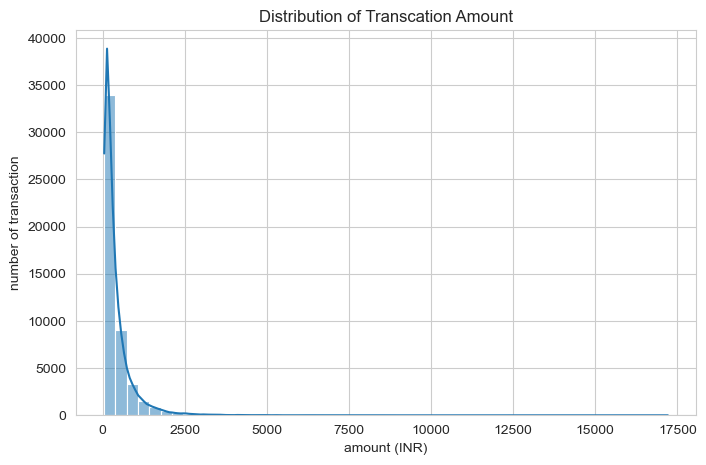

In [33]:
# chart1 : Transaction Amount distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['amount'], bins=50, kde=True)
plt.title("Distribution of Transcation Amount")
plt.xlabel("amount (INR)")
plt.ylabel("number of transaction")
plt.show()

# most transaction (38000) are in the 0-500 range.
# very few go beyond 2500inr showing platform is mainly used for small, everyday payments rather than high-value purchase.

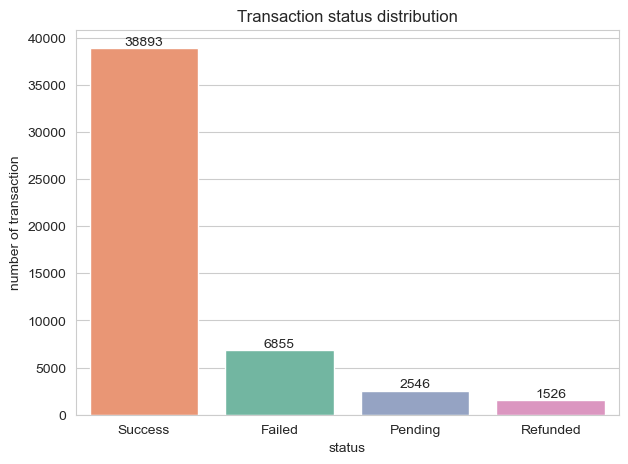

In [35]:
# chart 2: Transaction Status breakdown
# analyzing the proportion of success, failure, pending and refunded transaction to understand overall payment reliability
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='status', hue='status', order=df['status'].value_counts().index, palette='Set2')
plt.title('Transaction status distribution')
plt.xlabel('status')
plt.ylabel('number of transaction')

# add count label on the top of each bar
for container in ax.containers:
    ax.bar_label(container)
plt.show()

In [36]:
# calculate success rate and status percentages
status_counts = df['status'].value_counts()
status_percent = (status_counts / len(df)) * 100

print(status_counts)
print("\nPercentage:")
print(status_percent.round(2))





status
Success     38893
Failed       6855
Pending      2546
Refunded     1526
Name: count, dtype: int64

Percentage:
status
Success     78.07
Failed      13.76
Pending      5.11
Refunded     3.06
Name: count, dtype: float64


# 78% succesful, 14% failed, while failure rate is worth monitoring further analysis by gateway and payment method to help identify 
# reduce failure point

# busines use = fraud detectionn and risk scoring model treat high value transactioonn as higher priority for review

In [38]:
df['failure_reason'].value_counts()

failure_reason
Bank Declined         1704
Insufficient Funds    1653
Timeout               1614
Technical Error        833
Network Error          712
Invalid OTP            675
Limit Exceeded         557
Name: count, dtype: int64

# failre_reason cooumn to understand failures are mostly customer-side(bank/funds issue) or system-side(technical/network issue)

<function matplotlib.pyplot.show(close=None, block=None)>

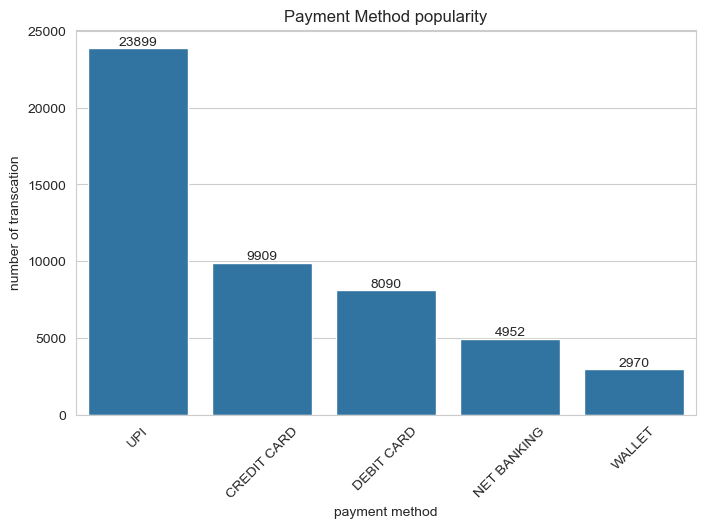

In [40]:
# chart 3: payment method popularity
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='payment_method', order=df['payment_method'].value_counts().index)
plt.title("Payment Method popularity")
plt.xlabel("payment method")
plt.ylabel("number of transcation")

for container in  ax.containers:
    ax.bar_label(container)
    
plt.xticks(rotation=45)
plt.show              

In [41]:
# percentage
df['payment_method'].value_counts(normalize=True).round(4) *100

payment_method
UPI            47.97
CREDIT CARD    19.89
DEBIT CARD     16.24
NET BANKING     9.94
WALLET          5.96
Name: proportion, dtype: float64

# Insight: upi is the most used payment mmethod(48%) top 3 method cover nearly 84% and upi showing higher dependency
# business impact: since upi handles the highest transcation volume and gateway performance for upi top priority

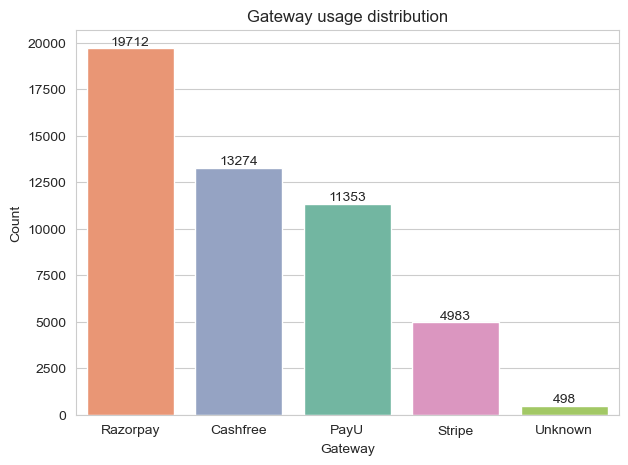

In [43]:
# chart 4 : Gateway usage distribution
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='gateway_name', order=df['gateway_name'].value_counts().index, hue='gateway_name', palette='Set2', legend=False)
plt.title("Gateway usage distribution")
plt.xlabel("Gateway")
plt.ylabel("Count")
for container in ax.containers:
    ax.bar_label(container)

                   

In [44]:
# percentage
df['gateway_name'].value_counts(normalize=True).round(4) *100

gateway_name
Razorpay    39.57
Cashfree    26.64
PayU        22.79
Stripe      10.00
Unknown      1.00
Name: proportion, dtype: float64

In [45]:
# Insight: razorpay is dominant gateway(40%), cashfre(26%) top 2 gateway handle 66% of total transaction volume
# buniess impact: heavy dependency on razor pay its time uptime and reliability should be the top monitoring priority
# with this single gateway disrupt 40% transaction a fell back mechanism to route trsnction to cashfree and payu during razorpay outages could reduce business risk


In [46]:
# additonal finding : Gateway-wise failure analysis showed
gateway_status = pd.crosstab(df['gateway_name'], df['status'], normalize='index') * 100
print(gateway_status.round(2))

status        Failed  Pending  Refunded  Success
gateway_name                                    
Cashfree       13.27     5.28      3.22    78.24
PayU           13.74     5.00      2.95    78.31
Razorpay       13.96     5.02      2.95    78.06
Stripe         14.39     5.28      3.33    77.00
Unknown        13.05     4.82      3.21    78.92


In [47]:
# u can see cleary all gateway same failure and success and there is no outlier and for business use better balance alerts , retry mechanism.


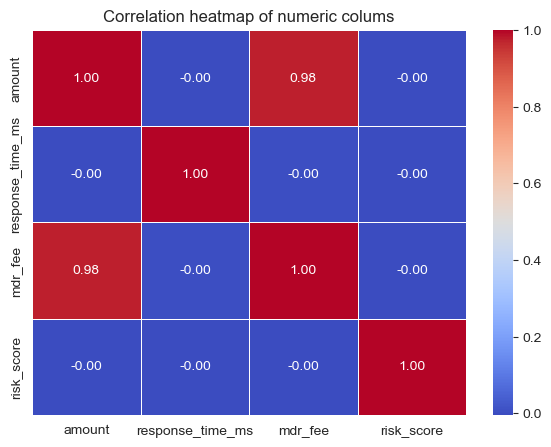

In [48]:
#chart 5: numeric correlation heatmap
numeric_colms = ['amount', 'response_time_ms', 'mdr_fee', 'risk_score']
corr_matrix = df[numeric_colms].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidth=0.5)
plt.title('Correlation heatmap of numeric colums')
plt.show()

In [49]:
# insight : mdr_fee is higly correlated with amount(0.98) and all other numeric colms(except amount) show no meaning correlation with amount or each other

# key insights summary

Data Cleaning:
- Removed 50 duplicate rows and 2 waves of corrupted `amount` outliers (placeholder values)
- Fixed missing values in gateway_name, issuer_bank, user_id, device_id (~1% random missingness)
- Standardized payment_method casing

**EDA Findings:**
- 78% of transactions succeed; 14% fail — of failures, 59% are customer/bank-side 
  (Bank Declined, Insufficient Funds), 41% are system-side (Timeout, Technical/Network Error)
- UPI dominates payment methods (48%), followed by Credit Card (20%) — top 2 cover 68%, 
  showing heavy dependency on UPI
- Razorpay is the dominant gateway (40%), followed by Cashfree (27%) — concentration risk 
  if Razorpay faces downtime
- mdr_fee is highly correlated with amount (0.98) — expected, since fee is calculated as 
  a percentage of transaction value
- Most transactions are small-value (₹0-500 range), indicating the platform is mainly 
  used for everyday payments
